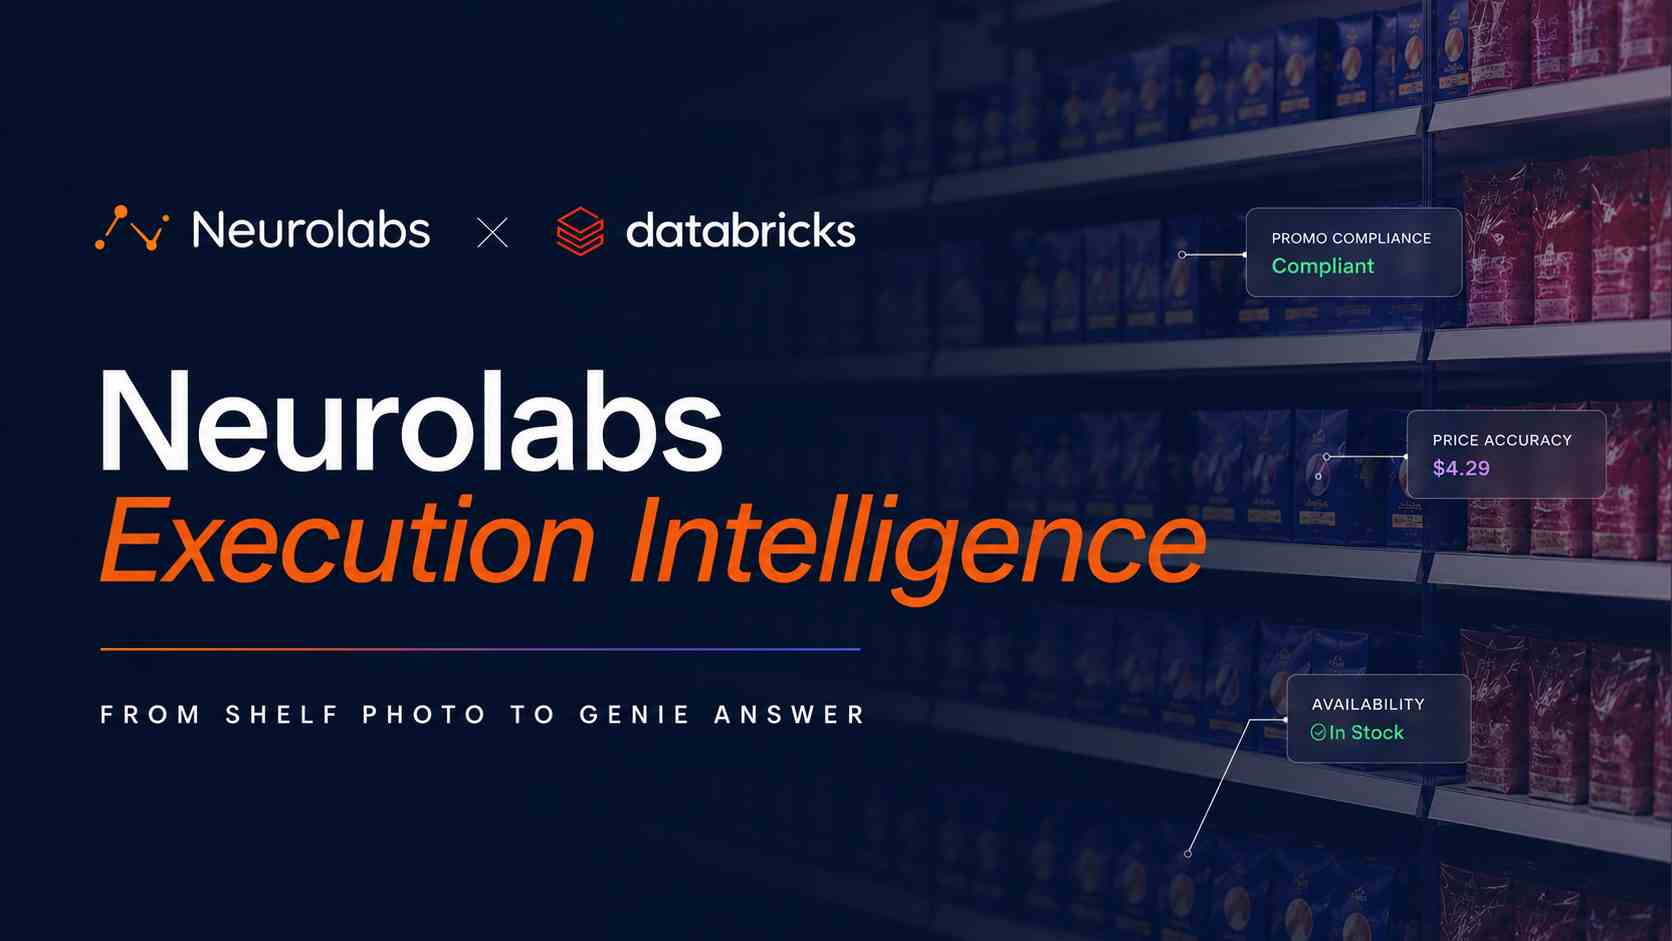




# Neurolabs Shelf Intelligence — Marketplace Quickstart


[![Open in Colab](https://img.shields.io/badge/Open%20in-Google%20Colab-orange?logo=google-colab&style=for-the-badge)](https://colab.research.google.com/github/neurolaboratories/zia-insights-dashboard/blob/main/neurolabs_marketplace_quickstart.ipynb)
[![Open in Vertex AI](https://img.shields.io/badge/Open%20in-Google%20Vertex%20AI%20Workbench-brightgreen?logo=google-cloud&style=for-the-badge)](https://console.cloud.google.com/vertex-ai/notebooks/deploy-notebook?download_url=https://raw.githubusercontent.com/neurolaboratories/zia-insights-dashboard/blob/main/neurolabs_marketplace_quickstart.ipynb)
[![Open in Databricks](https://img.shields.io/badge/databricks-red?logo=databricks&style=for-the-badge)](https://www.databricks.com/try-databricks)
[![View on GitHub](https://img.shields.io/badge/View%20on-GitHub-lightgrey?logo=github&style=for-the-badge)](https://github.com/neurolaboratories/zia-insights-dashboard/blob/main/neurolabs_marketplace_quickstart.ipynb)

This notebook walks through onboarding to the **Neurolabs Shelf Intelligence** data product, enriching the shared Gold schema with your own first-party data, and deploying the pre-built Databricks dashboard.

---

## Step 1 — Request access to the shared Gold schema

The Neurolabs data product exposes a read-only **Gold schema** via Databricks Delta Sharing. It contains six tables:

| Table | Description |
|---|---|
| `catalog` | Master product list with SKU, brand, category and planogram metadata |
| `subsection` | Shelf subsection definitions linked to outlet and aisle |
| `promo` | Promotional events with outlet, SKU, price and quantity |
| `shelf` | Raw shelf audit records with timestamps and surveyor IDs |
| `facing` | Individual product facings detected per shelf audit |
| `image` | Shelf image references and computer-vision job metadata |

### How to request access

1. Navigate to **Databricks Marketplace → Neurolabs Shelf Intelligence**
2. Click **Request access** and provide your Unity Catalog metastore name
3. Neurolabs will provision a Delta Share within 1 business day
4. Once approved, run the SQL cell below to attach the share to your metastore and verify table access

In [0]:
%sql
-- CELL 1: Attach the Neurolabs Delta Share and verify table access
-- Run this once after Neurolabs confirms your share has been provisioned

CREATE CATALOG IF NOT EXISTS demo_production
  USING SHARE neurolabs.demo_share;

USE CATALOG demo_production;
USE SCHEMA gold;

-- Confirm all six tables are accessible
-- List all tables
SHOW TABLES;

database,tableName,isTemporary
gold,catalog,false
gold,facing,false
gold,image,false
gold,promo,false
gold,shelf,false
gold,subsection,false


In [0]:
%sql
DESCRIBE TABLE catalog;

col_name,data_type,comment
catalog_uuid,string,Unique SKU identifier from the curated catalog.
annotation_catalog_item_id,bigint,Source annotation catalog item identifier used to build the SKU.
catalog_name,string,Display name of the SKU from the catalog.
catalog_brand,string,Normalized brand name for the SKU.
catalog_container_type,string,Container or packaging type recorded for the SKU.
catalog_flavour,string,Flavor or variant description for the SKU.
catalog_size,string,Pack size or size descriptor for the SKU.
trading_location,string,Normalized trading location associated with the SKU.
parent_company,string,Normalized parent company that owns the brand.
category_of_goods,string,Normalized product category assigned to the SKU.


In [0]:
%sql
DESCRIBE TABLE subsection;

col_name,data_type,comment
subsection_uuid,string,Unique subsection identifier built from outlet and campaign or task.
subsection_name,string,Display name for the subsection built from outlet and campaign or task.
lat,double,Latitude of the retail outlet for the subsection.
lng,double,Longitude of the retail outlet for the subsection.
city,string,City of the retail outlet.
region,string,Region or state of the retail outlet.
country_code,string,Country code of the retail outlet.
retail_outlet_name,string,Retail outlet name captured in the source annotation.
campaign_name,string,Campaign name associated with the subsection capture.
postcode,string,Postal code for the retail outlet.


In [0]:
%sql
DESCRIBE TABLE promo;

col_name,data_type,comment
catalog_uuid,string,"Catalog SKU identifier for the promoted item, or Unknown when unmatched."
price_uuid,string,"Composite price key made from price, quantity, and promo state."
price,double,Observed promo price value.
quantity,int,Observed quantity associated with the promo price.
days_to_median_up,int,Days from promo start until daily volume reaches or exceeds the median.
days_down_from_median,int,Days remaining from a below-median day until promo end.
promo_start,date,First observed date of the promo event.
promo_end,date,Last observed date of the promo event.
promo_weeks,double,Duration of the promo event measured in week-sized intervals.
distinct_promo_weeks,bigint,Number of distinct calendar weeks in which the promo was observed.


In [0]:
%sql
DESCRIBE TABLE shelf;

col_name,data_type,comment
result_uuid,string,Image result identifier containing the shelf.
result_dt_created,timestamp,Earliest available timestamp for the image result.
realogram_item_shelf_id,int,"Shelf identifier within the image result, or -1 when missing."
planogram_distance,double,Distance between this display and the most common display for this subsection and campaign.
assortment_brands,string,"Brand entry selected from planogram_brands using the matched assortment index, or an empty string when unavailable."
assortment,string,Planogram name if matched.
unknown_facings_in_shelf,bigint,Number of facings on the shelf without a matched catalog SKU.
unknown_share_of_shelf,bigint,Total annotated area occupied by unknown facings on the shelf.
known_facings_in_shelf,bigint,Number of facings on the shelf with a matched catalog SKU.
known_share_of_shelf,bigint,Total annotated area occupied by known facings on the shelf.


In [0]:
%sql
DESCRIBE TABLE facing;

col_name,data_type,comment
result_dt_created,timestamp,Earliest available timestamp for the image result.
catalog_uuid,string,"Catalog SKU identifier for the facing, or Unknown when unmatched."
subsection_uuid,string,Subsection identifier linking the facing to a store and campaign context.
result_uuid,string,Image result identifier containing the facing.
brand_distance,double,Distance between this display and Brand and the most common display and Brand for this subsection and campaign.
sku_distance,double,Distance between the display and SKU and the most common display and SKU for this subsection and campaign.
realogram_item_shelf_id,int,"Shelf identifier within the image result, or -1 when missing."
roi_id,int,Image region of interest identifier being summarized.
price_uuid,string,"Composite price key made from price, quantity, and promo state."
has_price,boolean,Whether the facing has a captured price.


In [0]:
%sql
DESCRIBE TABLE image;

col_name,data_type,comment
catalog_uuid,string,"Catalog SKU identifier summarized within the image, or Unknown when unmatched."
result_uuid,string,Image result identifier being summarized.
result_image_url,string,Processed image URL for the result.
result_original_image_url,string,Original source image URL for the result.
task_uuid,string,Task identifier that produced the image result.
roi_id,int,Image region of interest identifier being summarized.
result_dt_created,timestamp,Earliest available timestamp for the image result.
sku_at_eye_level_in_image,int,Flag indicating whether the SKU appears on shelf levels 2 or 3 in the image.
distinct_brand_facings_in_image,bigint,Number of distinct facings attributed to the brand in the image.
total_brand_facings_in_image,bigint,Total facings attributed to the brand in the image.


---

### Step 2 — Create a git folder and clone the Neurolabs public repo to view the dashboard [neurolaboratories/zia-insights-dashboard](https://github.com/neurolaboratories/zia-insights-dashboard)

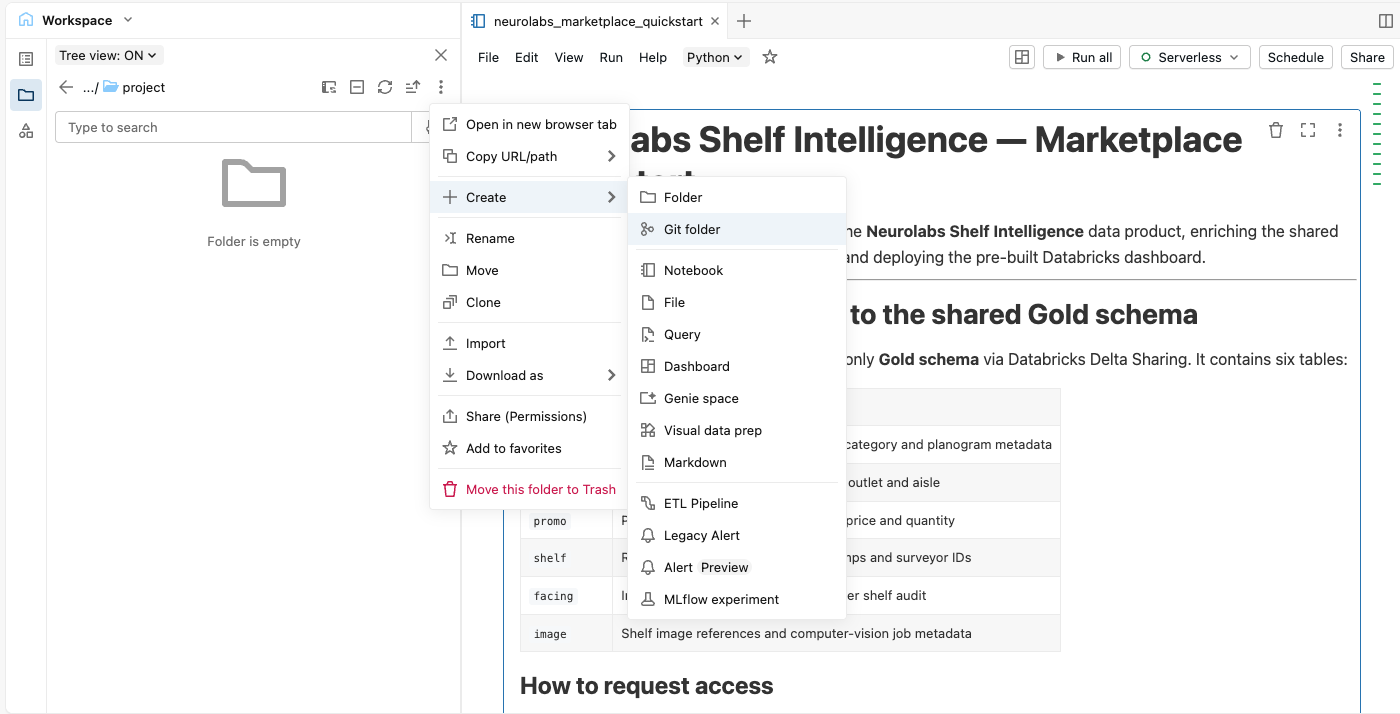


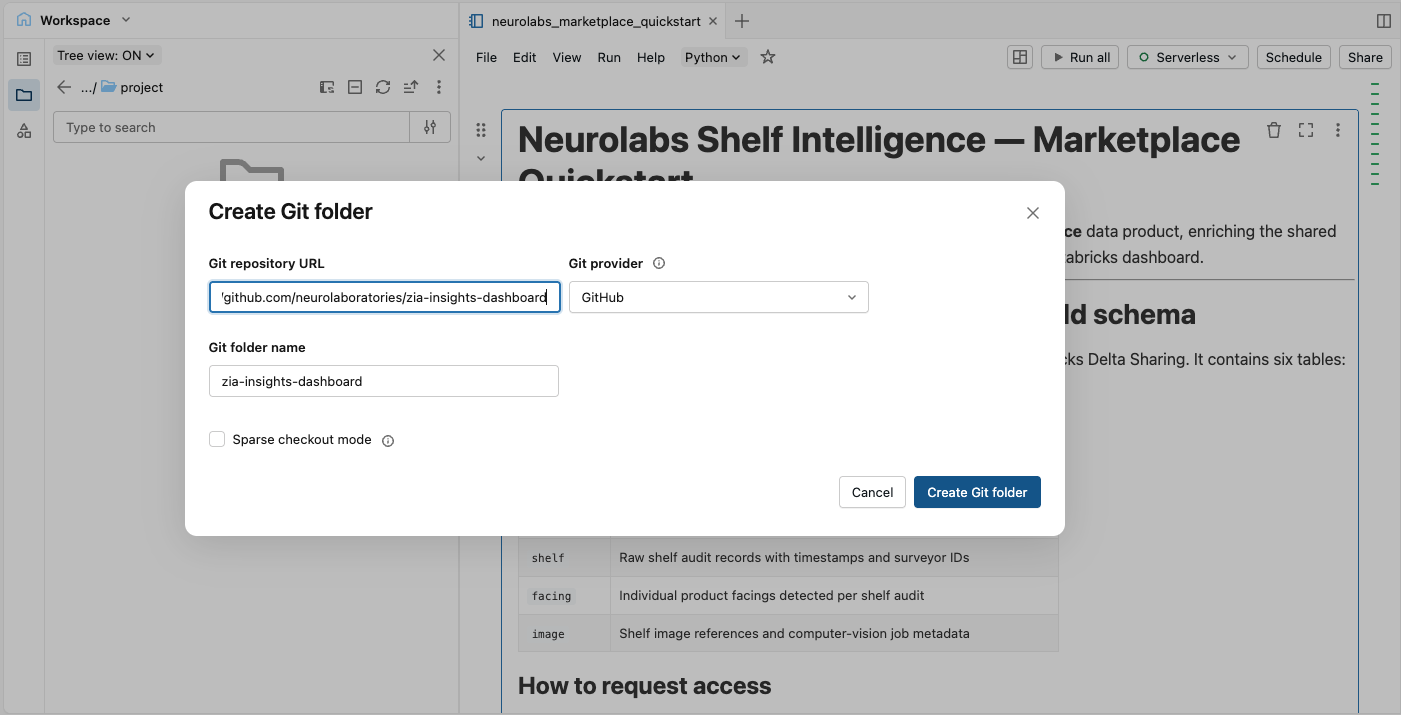


### Open the pre-built dashboard from the file menu (`dashboards/shelf_analytics.lvdash.json`) and select the catalog containing the delta shared tables with the **Organization** filter

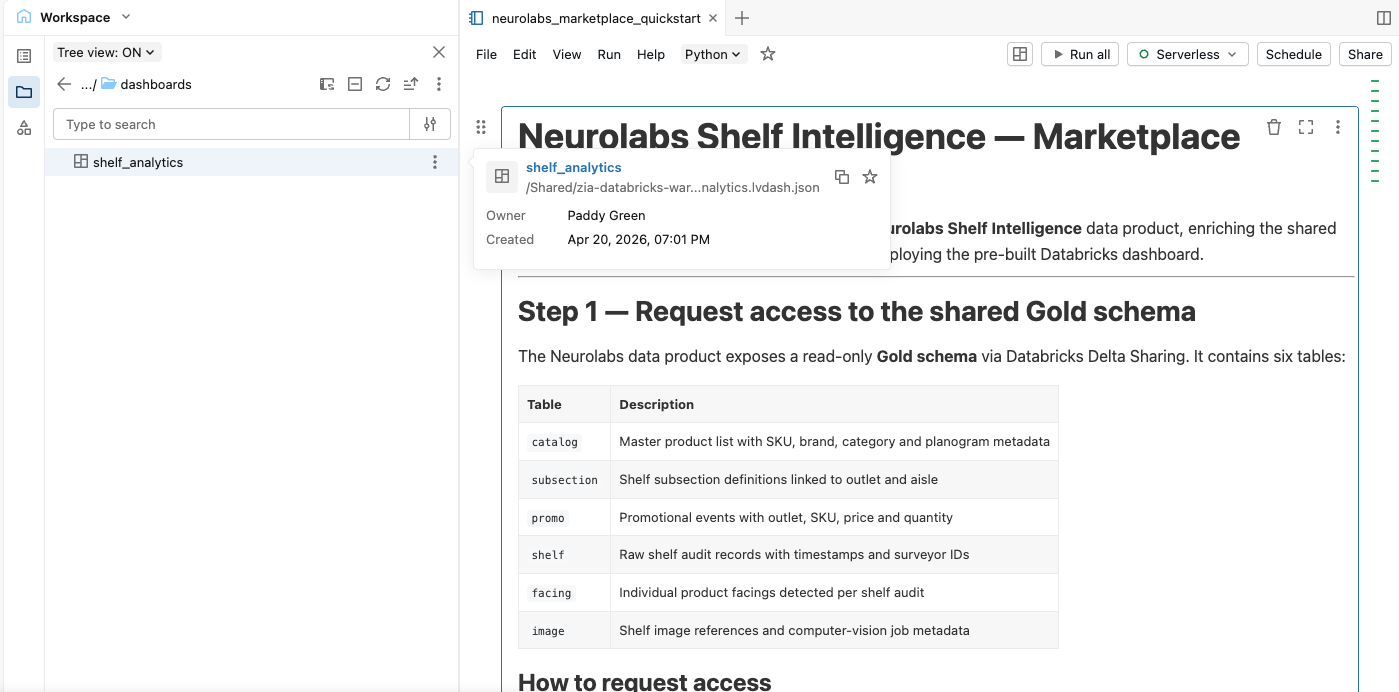

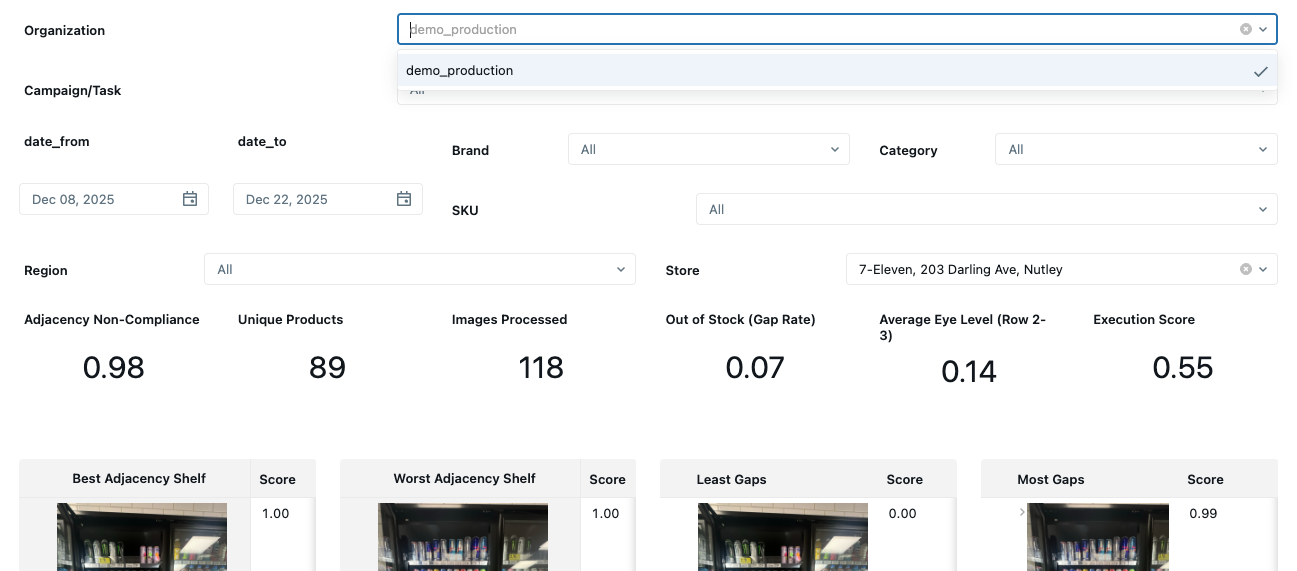


### Update the dashboard as you need and commit the changes to you're forked repo

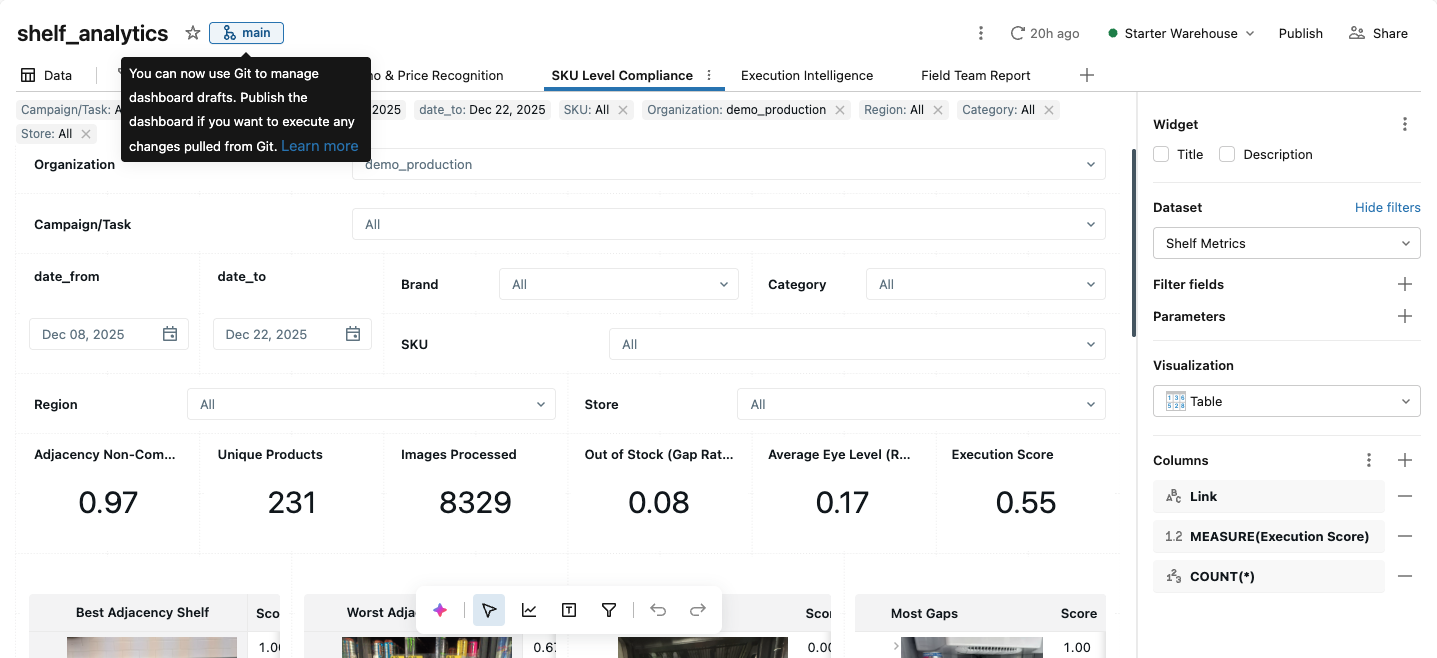

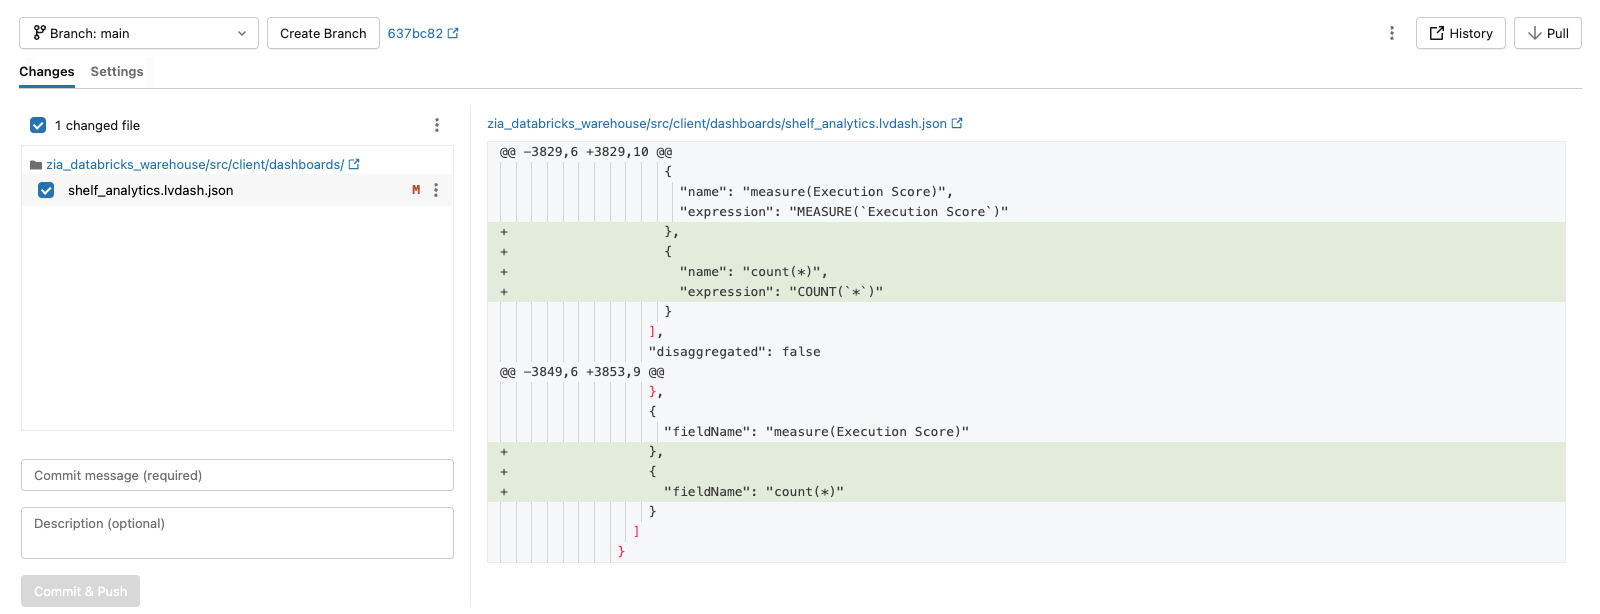


---
### Step 3 — Create you're genie space with the python cell below using the free script for generating a **Genie Spaces** from the all the **Calculated Fields** in your dashboard that have you have created to far (`scripts/deploy_genie_space.py`)

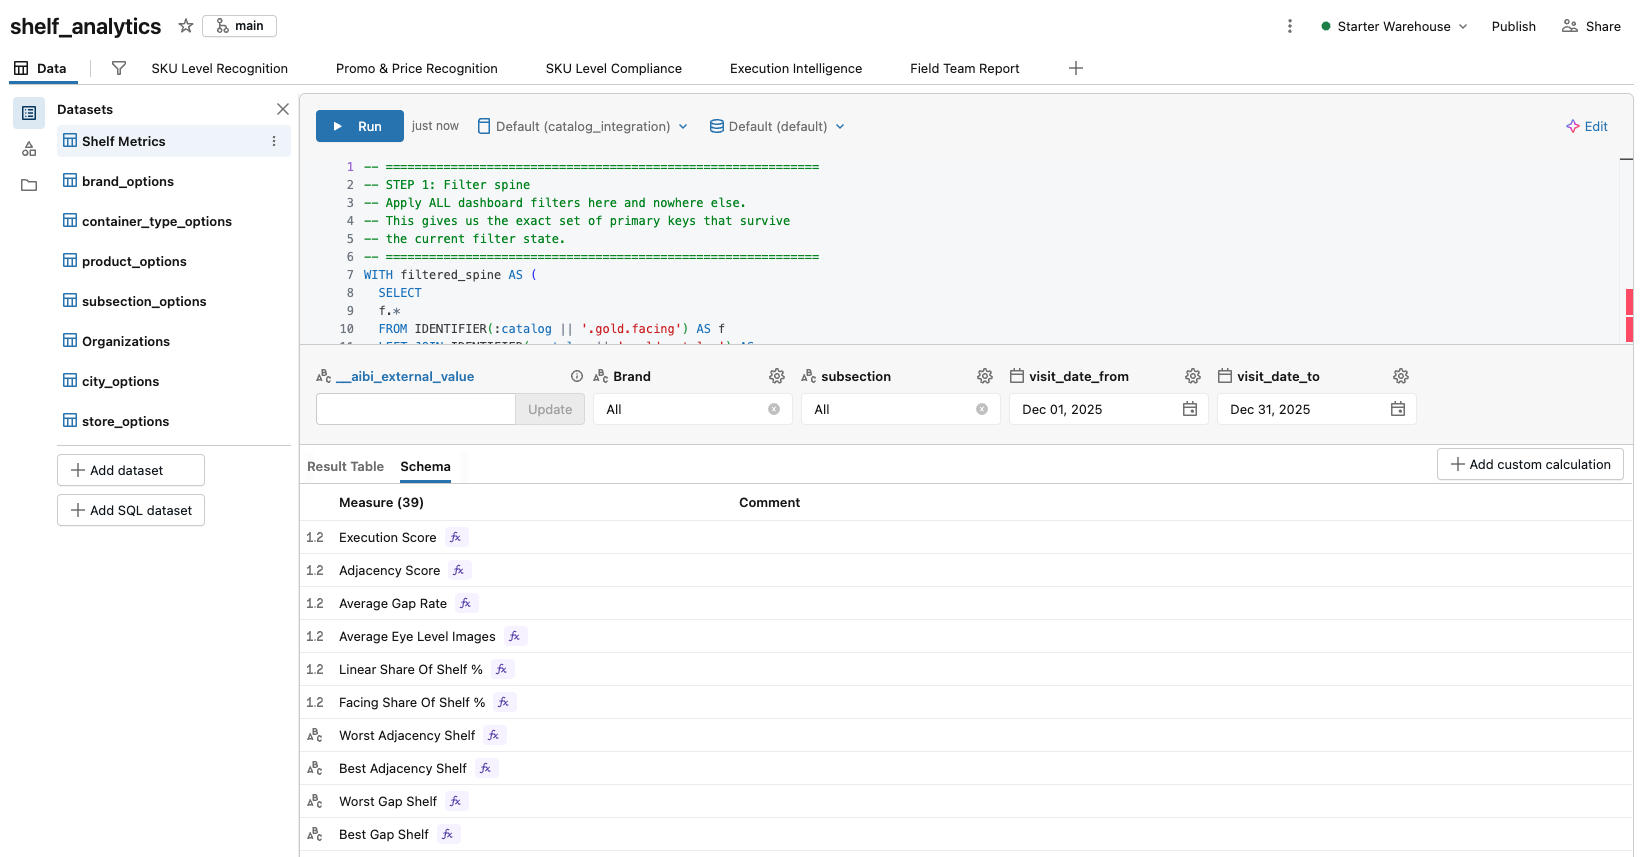

In [0]:
import os

# ── Edit this value to match your workspace ──────────────────────────────────
DATABRICKS_HOST = ""
REPO_DIR  = "/Workspace/Shared/"

# 2. Set environment and authenticate using the current notebook token
os.environ["DATABRICKS_HOST"]  = DATABRICKS_HOST
os.environ["DATABRICKS_TOKEN"] = (
    dbutils.notebook.entry_point.getDbutils().notebook().getContext()
    .apiToken().get()
)
os.environ["BUNDLE_TARGET"] = "production"
os.environ["WAREHOUSE_ID"] = ""
os.environ["GENIE_CATALOG"] = "demo"
os.environ["GENIE_PARENT_PATH"] = REPO_DIR

# 3. Create genie space
import sys
sys.path.insert(0, REPO_DIR)
from scripts.deploy_genie_space import main
main()

---
### You can now open the genie space file in /Workspace/Shared/ to ask questions and view you calculated fields

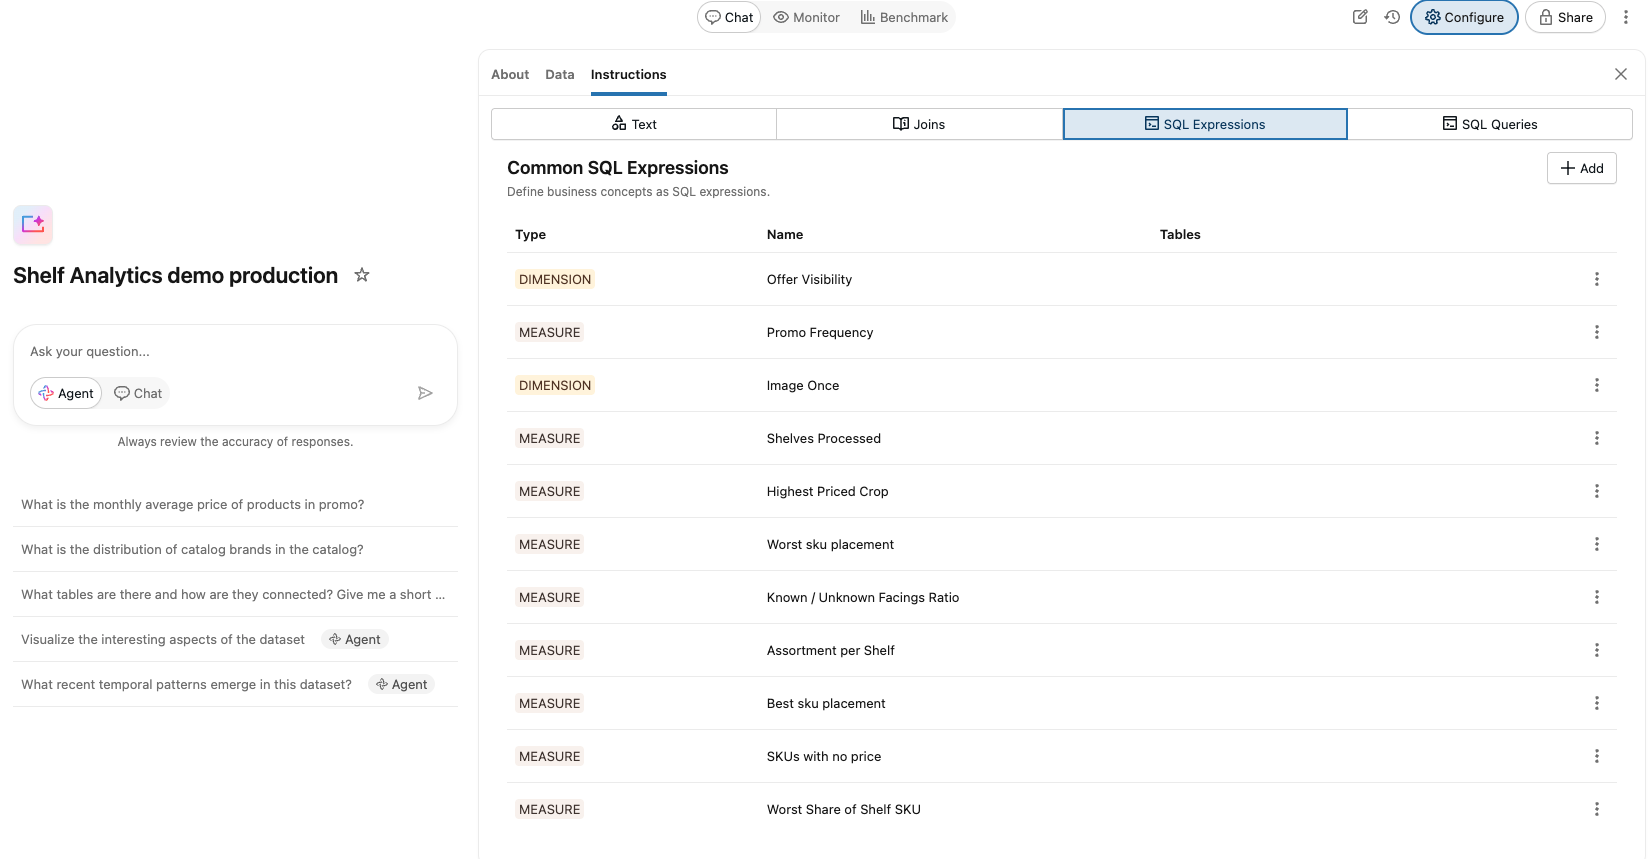


---

## (Optional) Step 3 — Enrich `catalog` with epos and inventory data (joined by SKU)

The shared `catalog` table contains planogram and category metadata per SKU. The cell below materialises a local enriched copy in `main.gold.catalog`, joining your internal data warehouse on `sku_name` to add:

- **Sales figures** — units sold (13-week and 52-week rolling), gross revenue, average selling price
- **Cost and margin data** — unit production cost, gross margin %, supplier lead time, reorder point

Replace `your_catalog.*` with your actual catalog and schema names.

In [0]:
%sql
-- CELL 3: Enrich catalog with sales and production cost data (joined by sku_name)

-- 1. Materialise a local enriched copy of the catalog table
CREATE OR REPLACE TABLE main.gold.catalog
AS SELECT
  c.*,

  -- Sales figures from your internal warehouse (joined on sku_name)
  s.units_sold_l13w,
  s.units_sold_l52w,
  s.gross_revenue_l13w_gbp,
  s.avg_selling_price_gbp,

  -- Production and margin data
  p.unit_production_cost_gbp,
  p.gross_margin_pct,
  p.supplier_lead_time_days,
  p.reorder_point_units

FROM      neurolabs_shared.gold.catalog        c
LEFT JOIN your_catalog.sales.sku_weekly_sales  s  ON c.sku_name = s.sku_name
LEFT JOIN your_catalog.finance.product_costs   p  ON c.sku_name = p.sku_name;

-- 2. Declarative schema — add columns for incremental / streaming updates
ALTER TABLE main.gold.catalog
  ADD COLUMNS IF NOT EXISTS (
    units_sold_l13w          BIGINT  COMMENT 'Units sold in last 13 weeks',
    units_sold_l52w          BIGINT  COMMENT 'Units sold in last 52 weeks',
    gross_revenue_l13w_gbp   DOUBLE  COMMENT 'Gross revenue last 13 weeks (GBP)',
    avg_selling_price_gbp    DOUBLE  COMMENT 'Average selling price (GBP)',
    unit_production_cost_gbp DOUBLE  COMMENT 'Unit production cost (GBP)',
    gross_margin_pct         DOUBLE  COMMENT 'Gross margin percentage',
    supplier_lead_time_days  INT     COMMENT 'Supplier lead time in days',
    reorder_point_units      INT     COMMENT 'Reorder point in units'
  );

SELECT * FROM main.gold.catalog LIMIT 5;

---

## (Optional) Step 4 — Enrich `subsection` with store demographic data (joined by outlet)

The shared `subsection` table links shelf subsections to outlets. The cell below joins Nielsen Homescan catchment data and your store CRM on `outlet_name` + `outlet_address` to add:

- **Store attributes** — format (superstore / convenience / express), retail banner, region, floor area
- **Nielsen Homescan demographics** — catchment population, median household income, age bands, shopper mission index, weekly footfall, category spend index

Replace `your_catalog.*` with your actual catalog and schema names.

In [0]:
%sql
-- CELL 4: Enrich subsection with Nielsen catchment & store-level demographics
--         Joined on outlet_name + outlet_address

CREATE OR REPLACE TABLE main.gold.subsection
AS SELECT
  ss.*,

  -- Store identifiers and format from your outlet master
  o.store_format,           -- e.g. 'superstore', 'convenience', 'express'
  o.retail_banner,
  o.region,
  o.store_sqft,

  -- Nielsen Homescan catchment demographics
  n.catchment_population,
  n.median_household_income_gbp,
  n.pct_families_with_children,
  n.pct_age_18_34,
  n.pct_age_55_plus,
  n.shopper_mission_index,   -- Nielsen index: 100 = national average
  n.weekly_footfall_estimate,
  n.category_spend_index     -- category spend vs national average (indexed)

FROM      neurolabs_shared.gold.subsection           ss
LEFT JOIN your_catalog.crm.outlet_master             o
       ON ss.outlet_name    = o.outlet_name
      AND ss.outlet_address = o.outlet_address
LEFT JOIN your_catalog.nielsen.catchment_profiles    n
       ON o.outlet_id       = n.outlet_id;

ALTER TABLE main.gold.subsection
  ADD COLUMNS IF NOT EXISTS (
    store_format                STRING  COMMENT 'Store format classification',
    retail_banner               STRING  COMMENT 'Retail banner / fascia',
    region                      STRING  COMMENT 'Geographic region',
    store_sqft                  INT     COMMENT 'Store floor area (sq ft)',
    catchment_population        INT     COMMENT 'Nielsen catchment population',
    median_household_income_gbp DOUBLE  COMMENT 'Median household income (GBP)',
    pct_families_with_children  DOUBLE  COMMENT '% households with children',
    pct_age_18_34               DOUBLE  COMMENT '% shoppers aged 18-34',
    pct_age_55_plus             DOUBLE  COMMENT '% shoppers aged 55+',
    shopper_mission_index       INT     COMMENT 'Nielsen shopper mission index (100 = avg)',
    weekly_footfall_estimate    INT     COMMENT 'Estimated weekly footfall',
    category_spend_index        INT     COMMENT 'Category spend vs national average (indexed)'
  );

SELECT * FROM main.gold.subsection LIMIT 5;

---

## (Optional) Step 5 — Enrich `promo` with marketing spend and channel data

The shared `promo` table records promotional events at the outlet × SKU × price × quantity level. The cell below joins your marketing attribution system on `outlet_name`, `sku_name`, `promo_price`, `promo_quantity`, and date range to add:

- **Campaign metadata** — campaign name, type (TPR / multibuy / display / feature), mechanic
- **Media investment** — total media spend, trade investment (co-op / listing fees), brand ATL spend
- **Channel mix** — TV, digital/social, OOH, in-store activation, email/CRM spend
- **Reach** — total impressions across all channels
- **Derived ROI metrics** — revenue per £1 media spend, cost per thousand impressions (CPM)

Replace `your_catalog.*` with your actual catalog and schema names.

In [0]:
-- CELL 5: Enrich promo with marketing attribution and channel investment data
--         Joined on outlet_name + sku_name + promo_price + promo_quantity + date range

CREATE OR REPLACE TABLE main.gold.promo
AS SELECT
  pr.*,

  -- Marketing campaign linkage
  mk.campaign_name,
  mk.campaign_type,           -- e.g. 'TPR', 'multibuy', 'display', 'feature'
  mk.promo_mechanic,

  -- Media investment
  mk.total_media_spend_gbp,
  mk.trade_investment_gbp,    -- co-op / listing fees paid to retailer
  mk.brand_investment_gbp,    -- above-the-line brand spend allocated to promo

  -- Reach and channel mix
  mk.total_reach_impressions,
  mk.tv_spend_gbp,
  mk.digital_spend_gbp,
  mk.ooh_spend_gbp,           -- out of home
  mk.instore_spend_gbp,       -- POS, display, leaflets
  mk.email_spend_gbp,
  mk.primary_channel,         -- highest-spend channel for this promo

  -- Derived ROI metrics
  ROUND(
    (pr.promo_price * pr.promo_quantity_sold) / NULLIF(mk.total_media_spend_gbp, 0),
  2) AS revenue_per_media_gbp,

  ROUND(
    mk.total_reach_impressions / NULLIF(mk.total_media_spend_gbp, 0),
  2) AS cost_per_thousand_impressions

FROM      neurolabs_shared.gold.promo              pr
LEFT JOIN your_catalog.marketing.promo_campaigns   mk
       ON  pr.outlet_name    = mk.outlet_name
      AND  pr.sku_name       = mk.sku_name
      AND  pr.promo_price    = mk.promo_price
      AND  pr.promo_quantity = mk.promo_quantity
      AND  pr.promo_start_date BETWEEN mk.campaign_start AND mk.campaign_end;

ALTER TABLE main.gold.promo
  ADD COLUMNS IF NOT EXISTS (
    campaign_name                 STRING  COMMENT 'Marketing campaign name',
    campaign_type                 STRING  COMMENT 'Promo type (TPR, multibuy, display, feature)',
    promo_mechanic                STRING  COMMENT 'Mechanic description',
    total_media_spend_gbp         DOUBLE  COMMENT 'Total media spend (GBP)',
    trade_investment_gbp          DOUBLE  COMMENT 'Trade / co-op investment (GBP)',
    brand_investment_gbp          DOUBLE  COMMENT 'Brand ATL investment (GBP)',
    total_reach_impressions       BIGINT  COMMENT 'Total media reach (impressions)',
    tv_spend_gbp                  DOUBLE  COMMENT 'TV spend (GBP)',
    digital_spend_gbp             DOUBLE  COMMENT 'Digital / social spend (GBP)',
    ooh_spend_gbp                 DOUBLE  COMMENT 'Out-of-home spend (GBP)',
    instore_spend_gbp             DOUBLE  COMMENT 'In-store activation spend (GBP)',
    email_spend_gbp               DOUBLE  COMMENT 'Email / CRM spend (GBP)',
    primary_channel               STRING  COMMENT 'Primary channel by spend',
    revenue_per_media_gbp         DOUBLE  COMMENT 'Revenue generated per £1 media spend',
    cost_per_thousand_impressions DOUBLE  COMMENT 'Cost per thousand impressions — CPM (GBP)'
  );

SELECT * FROM main.gold.promo LIMIT 5;

---

## (Optional) Next steps

Your enriched tables are now ready in `main.enriched` you can now switch the source data used in the Neurolabs Shelf Intelligence Dashboard with the top filter

**Recommended next steps:**

- **Schedule this notebook** as a Databricks Job to keep enrichment columns fresh on a daily cadence
- **Build Charts** just add your NEW company specific dimensions into the charts
- **Add Dashboard Filters** just add filters for your NEW company specific dimensions
- **Create NEW KPIs** just add your NEW company specific metrics into existing or new calculated columns